C:\Users\BCA25\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


--- Cluster-wise Average Spending (K=3) ---
            Annual_Spending  Visits_Per_Month
Cluster_K3                                   
0                   2268.18              9.91
1                   6541.67             17.50
2                    485.00              2.10



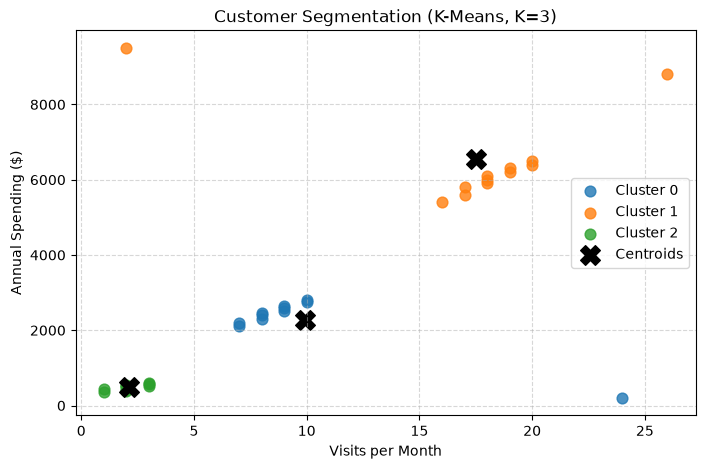

--- Metric Comparison (K=2, 3, 4) ---
K=2 | Inertia (Elbow): 20.82 | Silhouette Score: 0.6705
K=3 | Inertia (Elbow): 13.19 | Silhouette Score: 0.6967
K=4 | Inertia (Elbow): 7.24 | Silhouette Score: 0.7238



C:\Users\BCA25\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\BCA25\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\BCA25\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


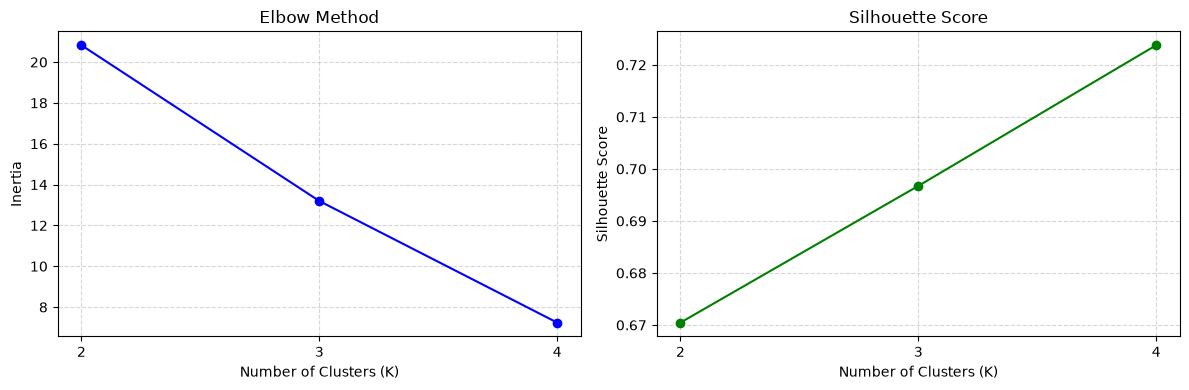

--- DBSCAN Cluster Counts ---
DBSCAN_Cluster
-1     3
 0    10
 1    10
 2    10
Name: count, dtype: int64


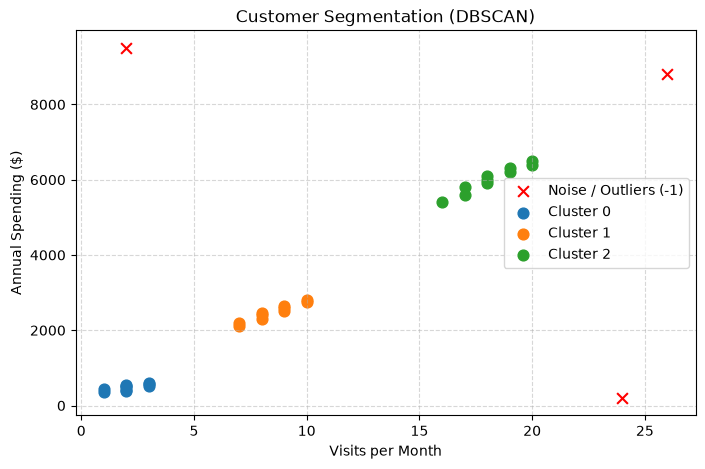

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score


data = {
    'Annual_Spending': [
        # Low spenders (10 customers)
        350, 420, 480, 510, 550, 600, 450, 520, 390, 580,
        # Medium spenders (10 customers)
        2100, 2300, 2450, 2500, 2600, 2750, 2200, 2400, 2650, 2800,
        # High spenders (10 customers)
        5400, 5600, 5900, 6100, 6300, 6500, 5800, 6000, 6200, 6400,
        # Outliers (3 customers - for DBSCAN to detect as -1)
        9500, 200, 8800
    ],
    'Visits_Per_Month': [
        # Low visits
        1, 2, 2, 3, 2, 3, 1, 2, 2, 3,
        # Medium visits
        7, 8, 8, 9, 9, 10, 7, 8, 9, 10,
        # High visits
        16, 17, 18, 18, 19, 20, 17, 18, 19, 20,
        # Outliers
        2, 24, 26
    ]
}

df = pd.DataFrame(data)


scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[['Annual_Spending', 'Visits_Per_Month']])

kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster_K3'] = kmeans_3.fit_predict(X_scaled)


print("--- Cluster-wise Average Spending (K=3) ---")
cluster_summary = df.groupby('Cluster_K3')[['Annual_Spending', 'Visits_Per_Month']].mean().round(2)
print(cluster_summary)
print()

plt.figure(figsize=(8, 5))
for cluster in sorted(df['Cluster_K3'].unique()):
    subset = df[df['Cluster_K3'] == cluster]
    plt.scatter(subset['Visits_Per_Month'], subset['Annual_Spending'], label=f'Cluster {cluster}', s=60, alpha=0.8)


centroids = scaler.inverse_transform(kmeans_3.cluster_centers_)
plt.scatter(centroids[:, 1], centroids[:, 0], c='black', marker='X', s=200, label='Centroids')

plt.title('Customer Segmentation (K-Means, K=3)')
plt.xlabel('Visits per Month')
plt.ylabel('Annual Spending ($)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


k_values = [2, 3, 4]
inertias = []
silhouettes = []

print("--- Metric Comparison (K=2, 3, 4) ---")
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertia = km.inertia_
    sil = silhouette_score(X_scaled, labels)
    
    inertias.append(inertia)
    silhouettes.append(sil)
    print(f"K={k} | Inertia (Elbow): {inertia:.2f} | Silhouette Score: {sil:.4f}")
print()


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(k_values, inertias, marker='o', color='b')
ax1.set_title('Elbow Method')
ax1.set_xlabel('Number of Clusters (K)')
ax1.set_ylabel('Inertia')
ax1.set_xticks(k_values)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.plot(k_values, silhouettes, marker='o', color='g')
ax2.set_title('Silhouette Score')
ax2.set_xlabel('Number of Clusters (K)')
ax2.set_ylabel('Silhouette Score')
ax2.set_xticks(k_values)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# ==========================================
# 5. Run DBSCAN
# ==========================================
dbscan = DBSCAN(eps=0.5, min_samples=3)
df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

print("--- DBSCAN Cluster Counts ---")
print(df['DBSCAN_Cluster'].value_counts().sort_index())

# Plot DBSCAN results
plt.figure(figsize=(8, 5))
for label in sorted(df['DBSCAN_Cluster'].unique()):
    subset = df[df['DBSCAN_Cluster'] == label]
    name = 'Noise / Outliers (-1)' if label == -1 else f'Cluster {label}'
    color = 'red' if label == -1 else None
    marker = 'x' if label == -1 else 'o'
    plt.scatter(subset['Visits_Per_Month'], subset['Annual_Spending'], label=name, c=color, marker=marker, s=60)

plt.title('Customer Segmentation (DBSCAN)')
plt.xlabel('Visits per Month')
plt.ylabel('Annual Spending ($)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()